# Weather Report: 86 years of climate in five European cities

**Question:** how has the climate of Milan, Palermo, Berlin, London and Madrid
changed from 1940 to 2025?

**Data:** daily maximum, minimum and mean temperature and precipitation from the
[Open-Meteo Historical Weather API](https://open-meteo.com/en/docs/historical-weather-api),
ERA5 reanalysis (Copernicus Climate Change Service).

**Method:** all the code lives in the `weather_report` package. This notebook only
imports its functions and tells the story of the analysis.

In [1]:
import sys
from pathlib import Path

# Make the project package importable from the notebooks/ folder
sys.path.insert(0, str(Path.cwd().parent))

In [2]:
from weather_report import analysis, plots, storage
from weather_report.config import CITIES, RECENT_PERIOD, REFERENCE_PERIOD
from weather_report.processing import build_tables

## 1. Loading the data

`build_tables` runs the whole pipeline: it reads the raw CSV cache
(downloading only the missing cities), cleans the data and builds
the daily, monthly and yearly tables.

In [3]:
tables = build_tables()
daily = tables["daily"]
monthly = tables["monthly"]
annual = tables["annual"]

Milan: loaded from milan_1940-01-01_2025-12-31.csv
Palermo: loaded from palermo_1940-01-01_2025-12-31.csv
Berlin: loaded from berlin_1940-01-01_2025-12-31.csv
London: loaded from london_1940-01-01_2025-12-31.csv
Madrid: loaded from madrid_1940-01-01_2025-12-31.csv
daily: saved to daily.csv
monthly: saved to monthly.csv
annual: saved to annual.csv


In [4]:
daily.shape, monthly.shape, annual.shape

((157060, 5), (5160, 5), (430, 5))

In [5]:
daily.head()

,temperature_2m_max,temperature_2m_min,temperature_2m_mean,precipitation_sum,city
time,,,,,
1940-01-01,2.3,-5.5,-1.8,NaN,Milan
1940-01-02,1.4,-5.3,-2.1,0.0,Milan
1940-01-03,-1.7,-6.0,-4.2,0.0,Milan
1940-01-04,3.2,-2.9,0.1,1.5,Milan
1940-01-05,5.8,-1.0,2.4,0.3,Milan


In [6]:
daily.isna().sum()

temperature_2m_max     0
temperature_2m_min     0
temperature_2m_mean    0
precipitation_sum      5
city                   0
dtype: int64

Five cities × 31,412 days = 157,060 rows in long format, with one `city` column.
Only a handful of values are missing: `mean` and `sum` simply skip them.

## 2. The climate of the five cities

Descriptive statistics of the daily mean temperature over the whole
period 1940-2025: mean, standard deviation, minimum and maximum.

In [7]:
summary = analysis.city_summary(daily)
summary

,mean,std,min,max
city,,,,
Berlin,9.27,7.87,-20.6,29.8
London,10.52,5.48,-8.7,29.1
Madrid,14.30,7.76,-8.8,32.8
Milan,13.10,8.06,-12.1,32.2
Palermo,18.60,6.32,2.0,36.9


In [8]:
path = storage.save_table(summary, "temperature_summary")

Palermo is the warmest city (mean 18.6 °C) and Berlin the coldest (9.3 °C).
The standard deviation measures how much daily temperature varies over the
year: it is largest in the continental climates (Milan, Berlin, Madrid) and smallest where
the sea mitigates temperatures (Palermo, London). The five cities really cover five
different climates.

## 3. Temperature anomalies

Each city has its own climate, so the cities are compare through the **anomaly**:
the difference between each year's mean temperature and the city's
climate normal, the 1961-1990 average (WMO standard reference period).

In [9]:
anomalies = analysis.annual_anomalies(annual)
anomalies.tail()

,city,anomaly
time,,
2021-01-01,Palermo,1.79
2022-01-01,Palermo,2.30
2023-01-01,Palermo,1.97
2024-01-01,Palermo,2.21
2025-01-01,Palermo,1.76


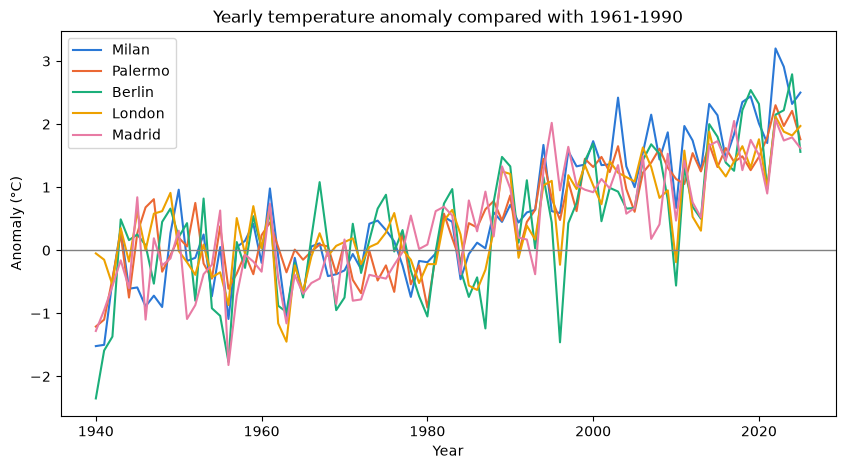

In [10]:
fig = plots.plot_anomalies(anomalies)
path = storage.save_figure(fig, "anomalies")

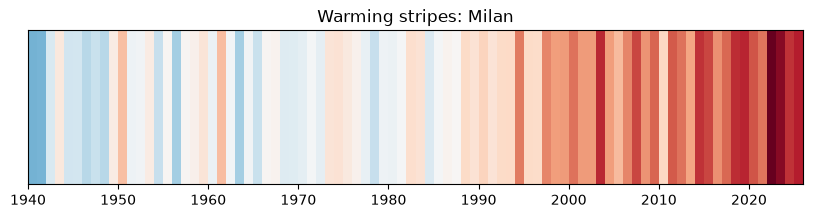

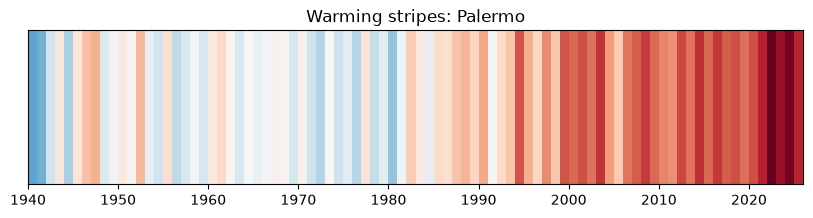

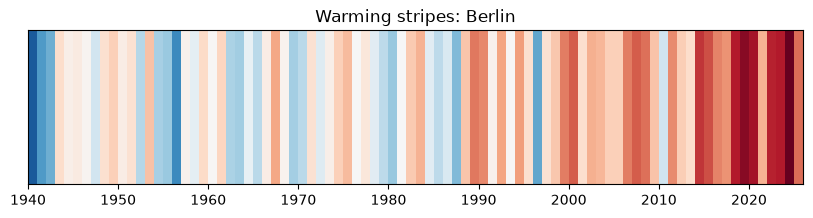

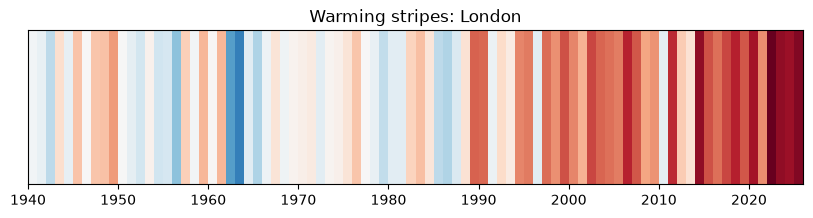

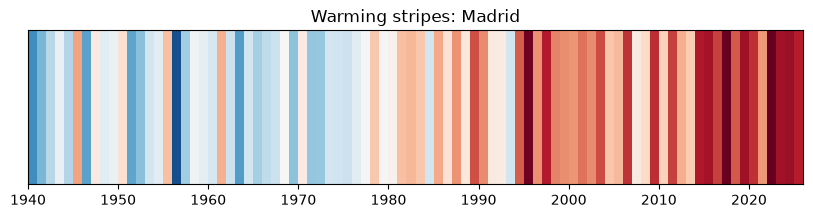

In [11]:
for city in CITIES:
    fig = plots.plot_warming_stripes(anomalies, city.name)
    path = storage.save_figure(fig, f"stripes_{city.slug}")

Until the 1980s the anomalies oscillate around zero. After that all five cities
warm up faster, and in the last decades almost every year is warmer than the
1961-1990 normal. The hot summers of 2003 and 2022 stand out. The warming stripes
show the same story at a glance: blue years in the first half of the period, red
years in the last decades.

## 4. Linear trends

A straight line fitted to the yearly mean temperatures (1940-2025) gives
the warming rate of each city in °C per decade. The p-value tests the
hypothesis that there is no trend at all.

In [12]:
trends = analysis.trend_table(annual)
trends

,slope_per_decade,r_squared,p_value
city,,,
Berlin,0.283,0.447,1.945093e-12
London,0.215,0.472,2.691086e-13
Madrid,0.288,0.624,1.599047e-19
Milan,0.370,0.735,5.639184e-26
Palermo,0.267,0.657,3.211718e-21


In [13]:
path = storage.save_table(trends, "temperature_trends")

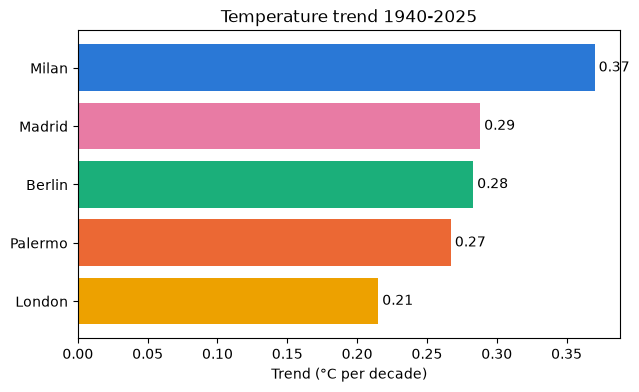

In [14]:
fig = plots.plot_trends(trends)
path = storage.save_figure(fig, "trends")

In [15]:
rain_trends = analysis.trend_table(annual, "precipitation_sum")
rain_trends

,slope_per_decade,r_squared,p_value
city,,,
Berlin,3.080,0.007,0.454661
London,18.397,0.201,0.000015
Madrid,-3.711,0.007,0.453644
Milan,10.986,0.011,0.328921
Palermo,1.872,0.001,0.755381


In [16]:
path = storage.save_table(rain_trends, "precipitation_trends")

In every city the last 30 years are warmer than the 1961-1990 normal, from
+1.21 °C in London to +1.80 °C in Milan. All p-values are far below 0.05: the
difference is not due to chance. This confirms the linear trends with a method
that does not assume a straight line.

Precipitation shows no real difference between the two periods: all p-values
are above 0.1, so the differences can be due to chance. As for the trends,
ERA5 is less reliable for rainfall than for temperature.

## 5. Comparing two climate periods

The mean temperature of the last 30 years (1996-2025) is compared with
the 1961-1990 normal. Welch's t-test checks whether the difference
could be due to chance (null hypothesis: same mean in both periods).

In [17]:
comparison = analysis.comparison_table(annual)
comparison

,early_mean,late_mean,difference,t_statistic,p_value
city,,,,,
Berlin,8.88,10.12,1.24,5.72,4.252249e-07
London,10.05,11.26,1.21,8.03,5.526886e-11
Madrid,13.94,15.16,1.22,8.15,4.696886e-11
Milan,12.51,14.31,1.80,12.88,4.119908e-18
Palermo,18.10,19.49,1.39,12.40,6.621927e-18


In [18]:
path = storage.save_table(comparison, "temperature_comparison")

In [19]:
rain_comparison = analysis.comparison_table(annual, "precipitation_sum")
rain_comparison

,early_mean,late_mean,difference,t_statistic,p_value
city,,,,,
Berlin,625.40,607.71,-17.69,-0.69,0.494391
London,626.92,660.33,33.41,1.34,0.185045
Madrid,469.75,421.70,-48.05,-1.62,0.110661
Milan,1191.36,1164.41,-26.95,-0.40,0.691883
Palermo,625.63,632.26,6.63,0.17,0.866172


In [20]:
path = storage.save_table(rain_comparison, "precipitation_comparison")

In every city the last 30 years are warmer than the 1961-1990 normal,
from +1.21 °C in London to +1.80 °C in Milan All p-values are far below 0.05:
the difference is not due to chance. This confirms the linear trends
with a method that does not assume a straight line.
As seen before the rain trends don't show a real statistic change (all the 
differences are inconsistent). This is partly linked to the poor ERA5
quality on precipitation collect.

## 6. Hot days

A hot day is a day with a maximum temperature of at least 30 °C.
Extremes matter more than averages for health, agriculture and energy.

In [21]:
hot = analysis.hot_days_per_year(daily)
hot.tail()

city,Berlin,London,Madrid,Milan,Palermo
year,,,,,
2021,7,0,72,43,85
2022,16,7,84,77,112
2023,10,1,80,49,87
2024,17,1,81,58,92
2025,12,4,96,51,100


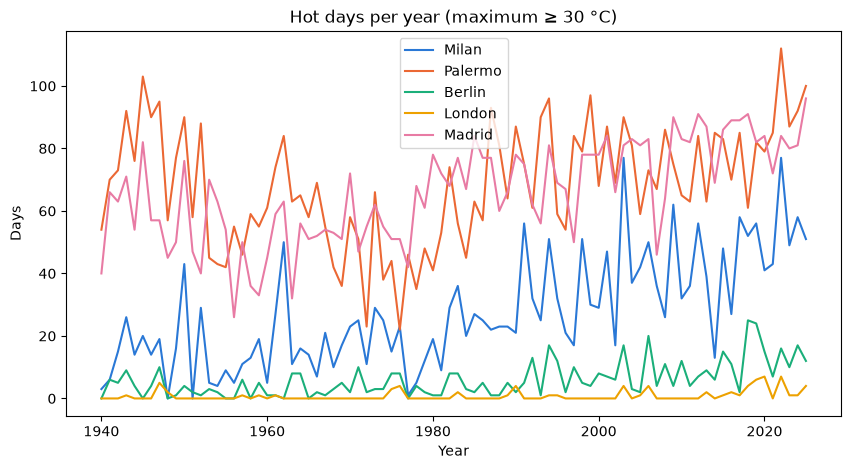

In [22]:
fig = plots.plot_hot_days(hot)
path = storage.save_figure(fig, "hot_days")

In [23]:
hot_periods = analysis.hot_days_by_period(hot)
hot_periods

,early_mean,late_mean
city,,
Berlin,3.6,9.8
London,0.5,1.5
Madrid,61.3,79.2
Milan,19.9,42.6
Palermo,56.4,78.8


In [24]:
path = storage.save_table(hot_periods, "hot_days_comparison")

Hot days have increased everywhere. In Milan they more than doubled,
from 19.9 per year in 1961-1990 to 42.6 in 1996-2025. Madrid and Palermo
already had many hot days and gained about 20 more per year. In Berlin
and London 30 °C is still rare, but it happens two to three times as often.

## 7. The seasonal cycle

The monthly mean temperature of Milan, year by year: each row is a year,
each column a month.

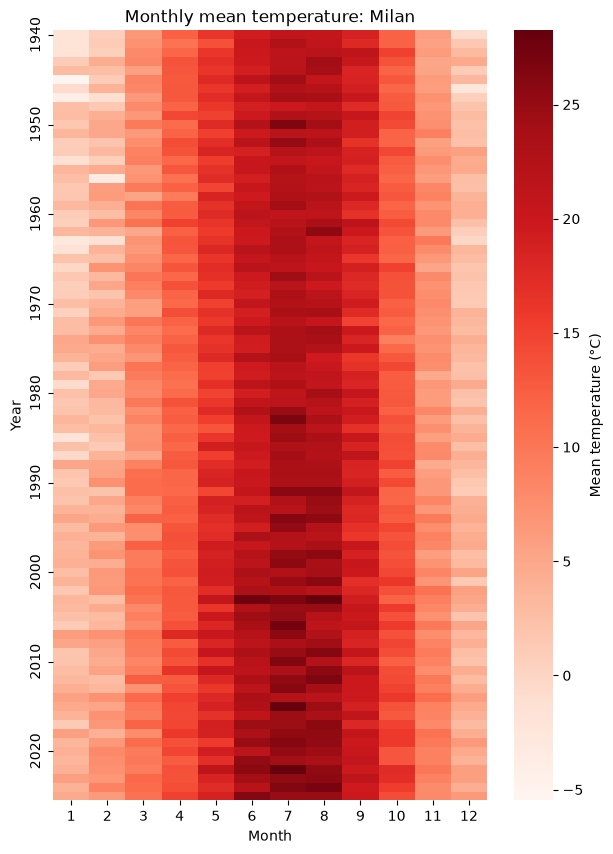

In [25]:
fig = plots.plot_monthly_heatmap(monthly, "Milan")
path = storage.save_figure(fig, "heatmap_milan")

The seasonal cycle dominates the chart: warm summers and cold winters. Going
down the rows, year by year, the summer months become warmer and the warm
season lasts a little longer.

## 8. Conclusions

**All five cities are warming.** The linear trends range from 0.22 °C per
decade in London to 0.37 °C in Milan, all with p-values below 1e-11.
Comparing the last 30 years with the 1961-1990 normal gives the same
answer with a different method: from +1.2 °C in Berlin, London and Madrid
to +1.8 °C in Milan.

**Milan is warming fastest.** It has the steepest trend, the largest
difference between the two periods and the largest increase in hot days:
from 19.9 to 42.6 per year, more than double.

**Extremes grow faster than averages.** A shift of 1-2 °C in the mean
temperature is enough to double or triple the number of days above 30 °C,
because the whole distribution moves towards the threshold.

**Rainfall shows no clear change.** Annual precipitation has no significant
trend, except London (+18 mm per decade), where the trend explains only
20% of the year-to-year variation.

## 9. Limits and next steps

- **ERA5 is a reanalysis**, not station data: each value is the average of
  a cell of about 25-30 km. It smooths extremes and does not see the urban
  heat island, so cities are actually hotter than shown here. Early
  decades and precipitation are less reliable, because fewer observations
  were available.
- **A straight line is an approximation.** The anomalies show that warming
  accelerated after the 1980s, so the 86-year trend underestimates the
  current rate.
- **The t-test assumes independent years**, while consecutive years are
  correlated. With p-values this small the conclusion does not change.
- **Five cities are not Europe.** They were chosen to cover five different
  climates, not to be a representative sample.

**Next steps:** automated tests with pytest, a heatmap of monthly anomalies,
more cities read from a configuration file.

All figures are saved in `outputs/figures/` and all result tables in
`outputs/tables/`.